# CA5 - Gradient Boosting

# Imports

In [2]:
import numpy as np, pandas as pd, optuna, matplotlib.pyplot as plt
from joblib import Parallel, delayed
import matplotlib.pyplot as plt


from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from sksurv.util import Surv
from sksurv.metrics import (concordance_index_censored, concordance_index_ipcw,
                            cumulative_dynamic_auc, brier_score, integrated_brier_score)
from sksurv.ensemble import ComponentwiseGradientBoostingSurvivalAnalysis
from sksurv.linear_model.coxph import BreslowEstimator


optuna.logging.set_verbosity(optuna.logging.WARNING)

## Reading Data & Preprocessing

In [3]:
# Reading data and filtering for death events only
df = pd.read_csv("colon.csv")
df = df[df["etype"] == 2].reset_index(drop = True) # death only

In [4]:
# Data cleaning and preprocessing
y = Surv.from_arrays(event = df["status"].astype(bool), time = df["time"])
X = df.drop(columns = ["id", "study", "etype", "time", "status"])

def make_prep(): # preprocessing pipeline
    num   = ["age", "nodes", "differ", "extent"]
    other = ["sex", "obstruct", "perfor", "adhere", "surg", "node4"]
    return ColumnTransformer([
        ("rx",  OneHotEncoder(drop="first", sparse_output=False), ["rx"]),
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                          ("sc",  StandardScaler())]), num),
        ("bin", SimpleImputer(strategy="most_frequent"), other),
    ])

## Task 1

In [5]:
# one fixed time grid, so curves from all 40 folds can be averaged pointwise
TIMES = np.linspace(np.percentile(y["time"], 10), np.percentile(y["time"], 90), 100)

N_TRIALS = 30
OUTER_FOLDS, OUTER_REPEATS = 4, 10
INNER_FOLDS, INNER_REPEATS = 4, 25

In [6]:
def suggest_params(trial):
    return {"n_estimators":  trial.suggest_int("n_estimators", 50, 500, step=50),
            "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.5, log=True),
            "subsample":     trial.suggest_float("subsample", 0.5, 1.0),
            "dropout_rate":  trial.suggest_float("dropout_rate", 0.0, 0.5)}

def build_model(p):
    return ComponentwiseGradientBoostingSurvivalAnalysis(loss="coxph", random_state=0, **p)

def surv_matrix(model, Atr, ytr, Ate, times):
    bz = BreslowEstimator().fit(model.predict(Atr), ytr["event"], ytr["time"])
    return np.vstack([fn(times) for fn in bz.get_survival_function(model.predict(Ate))])

In [7]:
def run_outer_fold(k, train_idx, test_idx):
    X_tr, y_tr = X.iloc[train_idx], y[train_idx]
    X_te = X.iloc[test_idx]

    # Inner loop: 4 folds * 25 repeats, stratified by event
    inner_splits = list(RepeatedStratifiedKFold(
        n_splits = INNER_FOLDS, n_repeats = INNER_REPEATS, random_state = k
    ).split(X_tr, y_tr["event"]))

    # Optuna objective: mean inner-loop IBS (to be minimised)
    def objective(trial):
        params = suggest_params(trial)
        ibs = []
        for i_tr, i_va in inner_splits:
            prep = make_prep()
            A_tr = prep.fit_transform(X_tr.iloc[i_tr])
            A_va = prep.transform(X_tr.iloc[i_va])
            try:
                model = build_model(params).fit(A_tr, y_tr[i_tr])
                S = surv_matrix(model, A_tr, y_tr[i_tr], A_va, TIMES)
                ibs.append(integrated_brier_score(y_tr[i_tr], y_tr[i_va], S, TIMES))
            except Exception:
                ibs.append(np.nan)
        return np.nanmean(ibs)

    study = optuna.create_study(direction="minimize",
                                sampler=optuna.samplers.TPESampler(seed = k))
    study.optimize(objective, n_trials=N_TRIALS)

    # Refit on the full outer-train set with the best hyperparameters
    prep = make_prep()
    A_tr = prep.fit_transform(X_tr)
    A_te = prep.transform(X_te)
    best_model = build_model(study.best_params).fit(A_tr, y_tr)

    # Store outer-fold predictions
    return {
        "fold": k,
        "repeat": k // OUTER_FOLDS,
        "train_idx": train_idx,
        "test_idx": test_idx,
        "best_params": study.best_params,
        "best_inner_ibs": study.best_value,
        "S_test": surv_matrix(best_model, A_tr, y_tr, A_te, TIMES), # survival curves
        "risk_test": best_model.predict(A_te), # risk scores
    }

In [8]:
outer_cv = RepeatedStratifiedKFold(n_splits = OUTER_FOLDS, n_repeats = OUTER_REPEATS,
                                   random_state = 42)

results = Parallel(n_jobs = -1)(
    delayed(run_outer_fold)(k, tr, te)
    for k, (tr, te) in enumerate(outer_cv.split(X, y["event"]))
)

len(results) # should be 40

40

In [9]:
pd.DataFrame([r["best_params"] for r in results]).describe()

,n_estimators,learning_rate,subsample,dropout_rate
count,40.000000,40.000000,40.000000,40.000000
mean,130.000000,0.025223,0.765084,0.196205
std,62.838825,0.016403,0.150545,0.169349
min,50.000000,0.010341,0.503688,0.001718
25%,50.000000,0.011625,0.646515,0.030371
50%,150.000000,0.017796,0.780042,0.164273
75%,200.000000,0.038842,0.895223,0.364267
max,250.000000,0.064249,0.985937,0.498986


The tuning was quite unstable for n_estimators (mean 130, std 63, anywhere from 50 to 250), so the model didn’t settle on one number of trees. The learning rate was small and fairly consistent (mean 0.025), subsample was usually around 0.65 to 0.9, and dropout_rate varied a lot (0.002 to 0.50), so those two didn’t have a clear best value.

## Task 2

In [10]:
def evaluate_fold(r):
    y_tr, y_te = y[r["train_idx"]], y[r["test_idx"]]
    S, risk = r["S_test"], r["risk_test"] # survival curves and risk scores

    _, bs = brier_score(y_tr, y_te, S, TIMES) # time-dependent Brier score
    auc, _ = cumulative_dynamic_auc(y_tr, y_te, risk, TIMES) # cumulative dynamic AUC

    return {
        "C_Harrell": concordance_index_censored(y_te["event"], y_te["time"], risk)[0],
        "C_Uno": concordance_index_ipcw(y_tr, y_te, risk, tau = TIMES[-1])[0],
        "IBS": integrated_brier_score(y_tr, y_te, S, TIMES),
        "BS": bs, # array over TIMES
        "AUC": auc, # array over TIMES
    }

metrics = [evaluate_fold(r) for r in results] # 40 entries

In [11]:
cols = ["C_Harrell", "C_Uno", "IBS"]

summary = pd.DataFrame({
    "mean": {c: np.mean([m[c] for m in metrics]) for c in cols},
    "std": {c: np.std ([m[c] for m in metrics]) for c in cols},
})

summary.round(4)

,mean,std
C_Harrell,0.6322,0.0229
C_Uno,0.6265,0.0245
IBS,0.2053,0.0060


The average Harrell’s C was 0.632 and Uno’s C was 0.627, so the model ranks patients only a little better than chance. The IBS was about 0.205, and the small standard deviations (around 0.023 for C and 0.006 for IBS) show the results didn’t change much between folds.

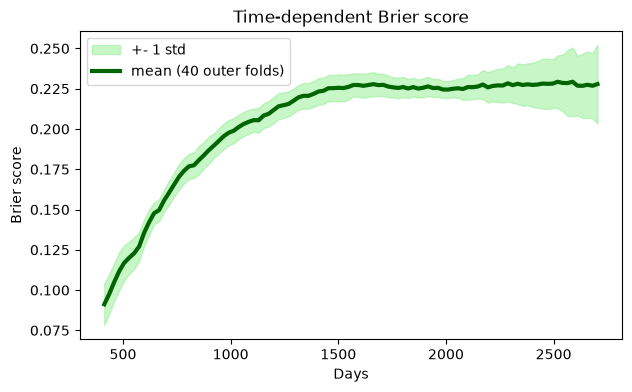

In [12]:
def plot_brier():
    M = np.vstack([m["BS"] for m in metrics]) # (40, n_times)
    mu, sd = M.mean(axis = 0), M.std(axis = 0)
    plt.figure(figsize = (7, 4))
    plt.fill_between(TIMES, mu - sd, mu + sd, color = "lightgreen", alpha = 0.5, label = "+- 1 std")
    plt.plot(TIMES, mu, color = "darkgreen", lw = 3, label = "mean (40 outer folds)")
    plt.xlabel("Days"); plt.ylabel("Brier score")
    plt.title("Time-dependent Brier score"); plt.legend(); plt.show()

plot_brier()

The Brier score starts low at about 0.09 around day 400, climbs quickly until about day 1500, then stays flat at roughly 0.225 for the rest of the follow-up. The band is narrow for most of the plot and only widens a little at the end, so the model's error is pretty consistent across folds. This is like both CoxPH models.

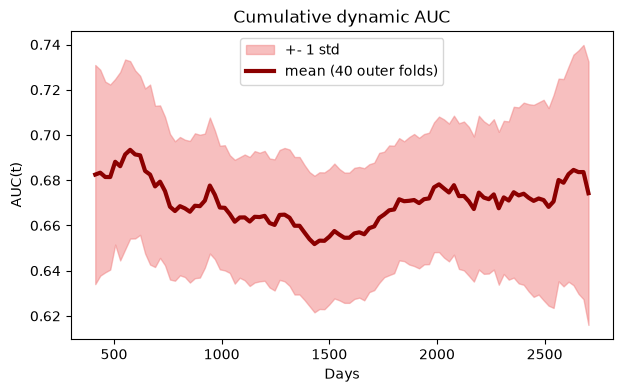

In [13]:
def plot_auc():
    M = np.vstack([m["AUC"] for m in metrics])
    mu, sd = M.mean(axis = 0), M.std(axis = 0)
    plt.figure(figsize = (7, 4))
    plt.fill_between(TIMES, mu - sd, mu + sd, color = "lightcoral", alpha = 0.5, label = "+- 1 std")
    plt.plot(TIMES, mu, color = "darkred", lw = 3, label = "mean (40 outer folds)")
    plt.xlabel("Days"); plt.ylabel("AUC(t)")
    plt.title("Cumulative dynamic AUC"); plt.legend(); plt.show()

plot_auc()

The AUC stays between about 0.65 and 0.69 the whole time, with a small peak near day 550 and a dip around day 1500 before going back up a bit. The shaded band is really wide everywhere, so the model's performance varies a lot between folds and it only separates patients weakly.

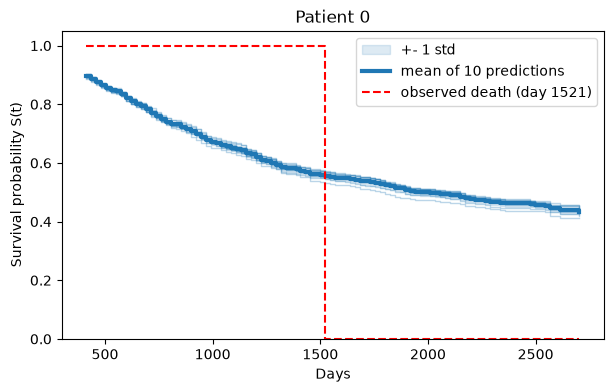

In [14]:
S_all = np.full((len(y), OUTER_REPEATS, len(TIMES)), np.nan)
for r in results:
    S_all[r["test_idx"], r["repeat"], :] = r["S_test"]

def plot_patient(patient):
    curves = S_all[patient] # (10, n_times)
    mu, sd = curves.mean(axis = 0), curves.std(axis = 0)
    t_i, e_i = y["time"][patient], y["event"][patient]

    plt.figure(figsize = (7, 4))
    for c in curves:
        plt.step(TIMES, c, where = "post", color = "tab:blue", alpha = 0.3, lw = 1)
    plt.fill_between(TIMES, mu - sd, mu + sd, step = "post",
                     color = "tab:blue", alpha = 0.15, label = "+- 1 std")
    plt.step(TIMES, mu, where = "post", color = "tab:blue", lw = 3, label = "mean of 10 predictions")

    # ground truth (dashed red)
    if e_i: # death observed: true survival drops to 0 at t_i
        plt.step(TIMES, (TIMES < t_i).astype(float), where = "post",
                 color = "red", ls = "--", label = f"observed death (day {t_i:.0f})")
    else: # censored: truth only known up to t_i
        mask = TIMES < t_i
        plt.plot(TIMES[mask], np.ones(mask.sum()), color = "red", ls = "--",
                 label = f"censored at day {t_i:.0f}")
        plt.plot([t_i], [1], "rx")

    plt.ylim(0, 1.05); plt.xlabel("Days"); plt.ylabel("Survival probability S(t)")
    plt.title(f"Patient {patient}"); plt.legend(); plt.show()

plot_patient(0)

Patient 0’s predicted survival goes down steadily from about 0.90 to around 0.44 at the end, and the 10 predictions are almost on top of each other, so the model is very consistent here. The patient died at day 1500, when the predicted survival was still about 60%, just like both CoxPH models

## AI Declaration

In accordance with NMBU’s guidelines on the use of generative artificial intelligence, 
I declare that I have used Claude (Anthropic) for language polishing and translation, 
for support in understanding the assignment text, 
and for guidance on implementing hyperparameter search with the Optuna library. 
All analysis and academic reasoning in this assignment are my own work, and the majority of the code was written by me. 
I remain solely responsible for the content and quality of the submission.